# Lab 7 — Go-to-goal: digits **26**

The last two digits of my student ID (**26**) are described as waypoints and driven with the go-to-goal controller, first in the TRIK Studio simulator and then on the real TRIK robot, with the **same program and the same gains**.

**Waypoints (cm)** — the robot starts at (0, 40) facing +x:

```
digit 2: (0,40) → (25,40) → (25,20) → (0,0) → (25,0)
gap:     (25,0) → (45,20)
digit 6: (45,20) → (70,20) → (70,0) → (45,0) → (45,40) → (70,40)
```

**Controller**

| | value |
|---|---|
| $K_v$ | 3 %/cm |
| $v_{max}$ / $v_{min}$ | 60 % / 20 % |
| $K_\theta$ | 50 %/rad |
| acceptance radius $\varepsilon$ | 3 cm |
| turn in place when | $|e_\theta| > 0.5$ rad |
| $r$, $B$ | sim 2.8 / 15.4 cm, real 4.2 / 19.4 cm |

$\rho = \sqrt{(x_g-x)^2+(y_g-y)^2}$, $\theta_g = \operatorname{atan2}(y_g-y,\,x_g-x)$, $e_\theta = \operatorname{wrap}(\theta_g-\theta)$  
$v = \min(K_v\rho, v_{max})$ (kept $\ge v_{min}$; $v = 0$ if $|e_\theta| > 0.5$ rad), $\omega = K_\theta e_\theta$  
right wheel (M4) $= v+\omega$, left wheel (M3) $= v-\omega$; switch to the next waypoint when $\rho < \varepsilon$.

In [1]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

try:                                # in Google Colab: select BOTH txt files
    from google.colab import files
    uploaded = files.upload()
except ImportError:                 # running locally: files are next to the notebook
    pass

In [2]:
# Planned waypoints (same as in the TRIK program, start point first)
wp = np.array([[0, 40], [25, 40], [25, 20], [0, 0], [25, 0],          # digit 2
               [45, 20],                                               # gap
               [70, 20], [70, 0], [45, 0], [45, 40], [70, 40]])        # digit 6

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)
print(f'sim: {len(x_s)} samples, real: {len(x_r)} samples')

sim: 2981 samples, real: 303 samples


## 1. Planned path vs simulated vs real

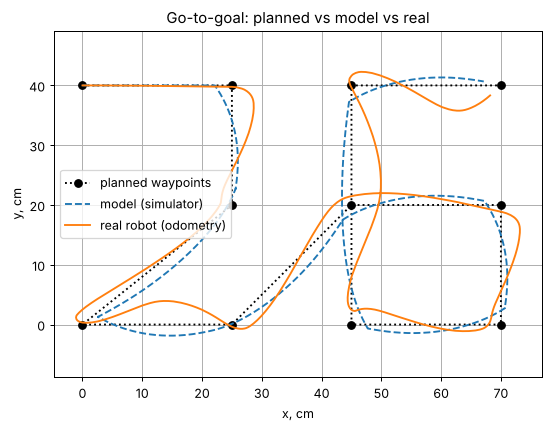

In [3]:
plt.figure(figsize=(7, 5))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

## 2. How close did each run get to each waypoint?

In [4]:
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s, wp)
miss_r = waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i:2d} {str(tuple(wp[i].tolist())):9s}: sim {ms:4.1f} cm | real {mr:4.1f} cm')
print(f'Largest miss: sim {miss_s.max():.1f} cm | real {miss_r.max():.1f} cm')

Waypoint  0 (0, 40)  : sim  0.0 cm | real  0.0 cm
Waypoint  1 (25, 40) : sim  2.4 cm | real  0.2 cm
Waypoint  2 (25, 20) : sim  0.6 cm | real  1.9 cm
Waypoint  3 (0, 0)   : sim  2.9 cm | real  0.3 cm
Waypoint  4 (25, 0)  : sim  0.2 cm | real  0.3 cm
Waypoint  5 (45, 20) : sim  1.5 cm | real  1.4 cm
Waypoint  6 (70, 20) : sim  2.0 cm | real  1.2 cm
Waypoint  7 (70, 0)  : sim  2.0 cm | real  1.9 cm
Waypoint  8 (45, 0)  : sim  2.1 cm | real  2.3 cm
Waypoint  9 (45, 40) : sim  2.2 cm | real  0.2 cm
Waypoint 10 (70, 40) : sim  2.9 cm | real  2.5 cm
Largest miss: sim 2.9 cm | real 2.5 cm


## 3. Run time

In [5]:
print(f'Run time: sim {(t_s[-1]-t_s[0])/1000:.1f} s | real {(t_r[-1]-t_r[0])/1000:.1f} s')

Run time: sim 29.8 s | real 13.8 s


## 4. End point

Where the real robot finished by its own odometry, compared with the last waypoint.

In [6]:
last_wp  = wp[-1]
last_odo = np.array([x_r[-1], y_r[-1]])
print(f'Last waypoint                  : {tuple(last_wp.tolist())}')
print(f'Last line of odometry_data_real: ({last_odo[0]:.1f}, {last_odo[1]:.1f})')
print(f'Distance to last waypoint      : {np.linalg.norm(last_odo - last_wp):.1f} cm')

Last waypoint                  : (70, 40)
Last line of odometry_data_real: (68.2, 38.3)
Distance to last waypoint      : 2.5 cm


## 5. Conclusions

**Which corners were cut or overshot, and why?** In the simulator the corners are only slightly rounded: the robot switches to the next waypoint as soon as $\rho < \varepsilon = 3$ cm, so it never reaches the exact corner. On the real robot the corners are overshot instead: after (25, 40) it swings out to $x \approx 29$ cm, the left stroke of the 6 bulges out to $x \approx 50$ cm and the last top bar sags to $y \approx 36$ cm. This comes from the turn-in-place threshold of 0.5 rad together with $v_{max} = 60$ %: the robot starts driving while still up to ~29° off course, and the slower real motors let it overshoot before $K_\theta = 50$ pulls it back, so the segments become S-shaped. A smaller threshold (≈ 0.15 rad) or a lower $v_{max}$ would give sharper digits but a slower run.

**Control or localization?** By odometry both runs pass every waypoint within about $\varepsilon$ (largest miss: sim 2.9 cm, real 2.5 cm) and the real robot ends 2.5 cm from the last waypoint, so the controller reaches every goal it is given; the S-curves are a tuning issue. Odometry only shows where the robot *thinks* it is, so any remaining real-vs-model gap is a **localization** problem (wheel slip, errors in $r$ and $B$), which the controller cannot see or correct.